# Mount Google Drive and Link Datasets

In [ ]:
# Create base data directory
!mkdir -p /content/data

# Link ISIC2019 (source)
!ln -s "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged" /content/data/ISIC2019

# Link Fitzpatrick17k (unlabeled target)
!ln -s "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled/dummy" /content/data/Fitzpatrick17k

# Link labeled Fitzpatrick subset for evaluation
!ln -s "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected" /content/data/Fitzpatrick17k_test

In [ ]:
# -------------------------
# Clean install for PyTorch + DA
# -------------------------

!pip install --upgrade pip
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118

# Basic deps
!pip install numpy scipy tqdm pandas scikit-learn matplotlib seaborn

# Image processing
!pip install pillow opencv-python

# Optional but recommended
!pip install albumentations

# Debug utilities (optional)
!pip install rich supervision


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 34.1 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
Looking in indexes: https://download.pytorch.org/whl/cu118


In [ ]:
import torch
import torchvision

print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


# Install Dependencies

In [ ]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
!pip install scikit-learn pandas tqdm matplotlib seaborn


Looking in indexes: https://download.pytorch.org/whl/cu118


# Run ADDA Training

In [ ]:
!python "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/adda_vgg16.py" \
  --source-dir /content/data/ISIC2019 \
  --target-dir /content/data/Fitzpatrick17k \
  --test-dir /content/data/Fitzpatrick17k_test \
  --out-dir /content/drive/MyDrive/Colab\ Results/ADDA_VGG16BN \
  --batch-size 16 \
  --pretrain-epochs 20 \
  --adapt-epochs 40 \
  --use-focal


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_BN_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_BN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth
100% 528M/528M [00:02<00:00, 219MB/s]
>>> Pretraining source encoder + classifier
Pretrain Ep 1/20: 100% 1567/1567 [1:23:46<00:00,  3.21s/it, acc=0.684, loss=0.156]
Pretrain epoch 1 loss=0.1257 acc=0.6844
Pretrain Ep 2/20: 100% 1567/1567 [03:52

# View Evaluation Results

,precision,recall,f1-score,support
ak,0.000000,0.000000,0.000000,175.000000
bcc,0.219780,0.120000,0.155239,500.000000
bkl,0.000000,0.000000,0.000000,69.000000
df,0.000000,0.000000,0.000000,79.000000
mel,0.252809,0.180000,0.210280,500.000000
nv,0.137063,0.830508,0.235294,236.000000
scc,0.000000,0.000000,0.000000,500.000000
accuracy,0.168043,0.168043,0.168043,0.168043
macro avg,0.087093,0.161501,0.085831,2059.000000
weighted avg,0.130472,0.168043,0.115731,2059.000000


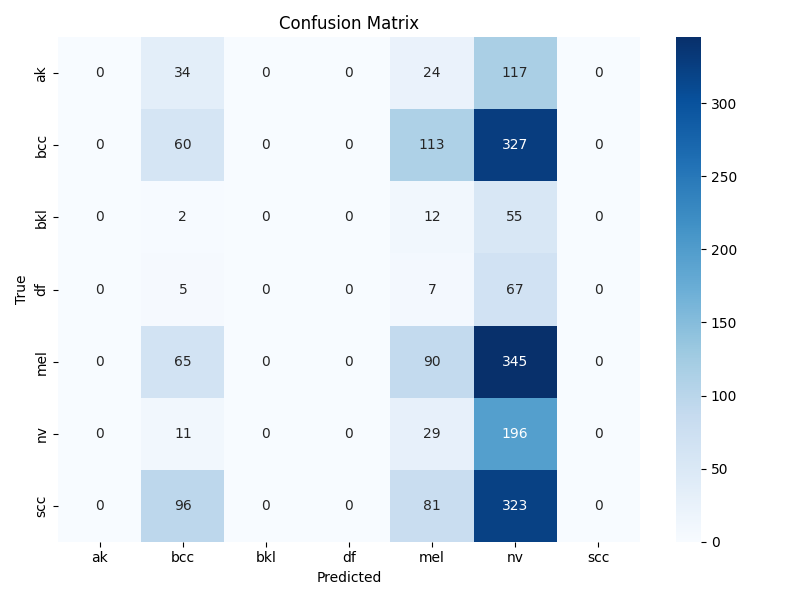

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Load classification report
report_path = "/content/drive/MyDrive/Colab Results/ADDA_VGG16BN/classification_report.csv"
df = pd.read_csv(report_path, index_col=0)
display(df)

# Show confusion matrix
cm_path = "/content/drive/MyDrive/Colab Results/ADDA_VGG16BN/confusion_matrix.png"
display(Image(filename=cm_path))


Loaded encoder weights.
Missing keys: ['0.weight', '0.bias', '1.weight', '1.bias', '1.running_mean', '1.running_var', '3.weight', '3.bias', '4.weight', '4.bias', '4.running_mean', '4.running_var', '7.weight', '7.bias', '8.weight', '8.bias', '8.running_mean', '8.running_var', '10.weight', '10.bias', '11.weight', '11.bias', '11.running_mean', '11.running_var', '14.weight', '14.bias', '15.weight', '15.bias', '15.running_mean', '15.running_var', '17.weight', '17.bias', '18.weight', '18.bias', '18.running_mean', '18.running_var', '20.weight', '20.bias', '21.weight', '21.bias', '21.running_mean', '21.running_var', '24.weight', '24.bias', '25.weight', '25.bias', '25.running_mean', '25.running_var', '27.weight', '27.bias', '28.weight', '28.bias', '28.running_mean', '28.running_var', '30.weight', '30.bias', '31.weight', '31.bias', '31.running_mean', '31.running_var', '34.weight', '34.bias', '35.weight', '35.bias', '35.running_mean', '35.running_var', '37.weight', '37.bias', '38.weight', '38.bia

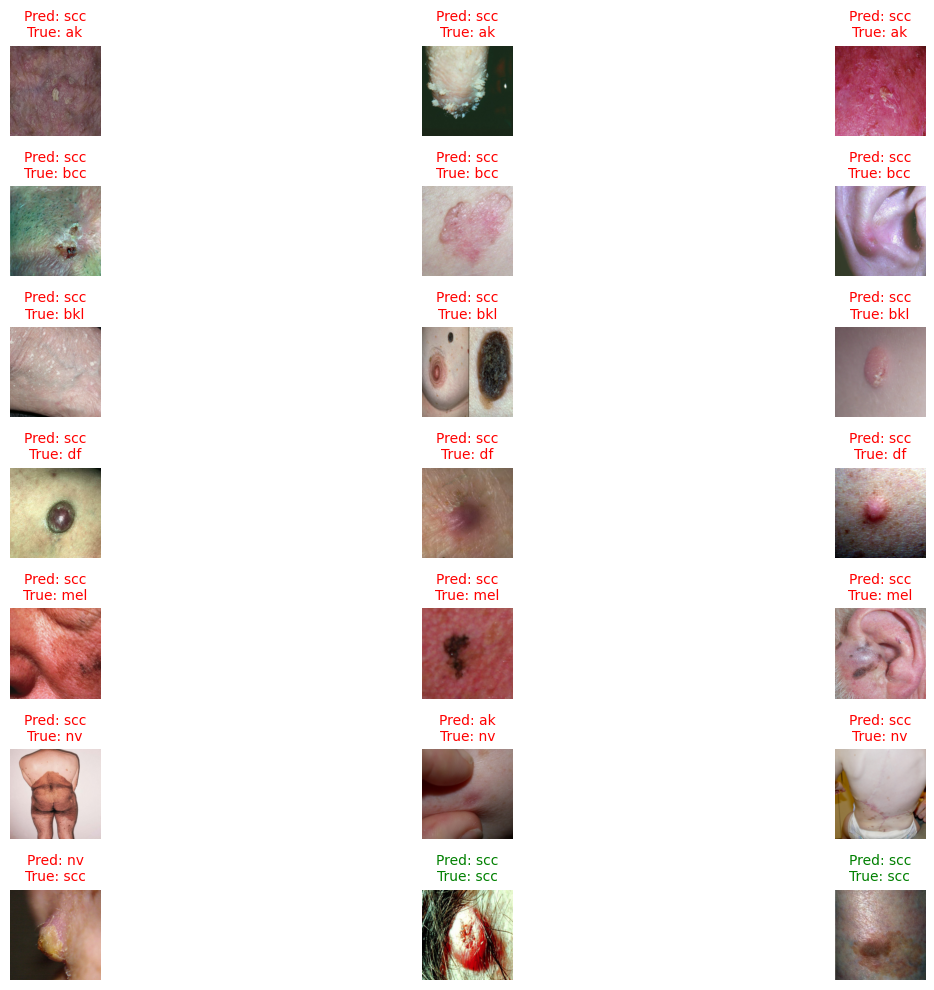

In [ ]:
import torch
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import os

# ✅ Paths
model_path = "/content/drive/MyDrive/Colab Results/ADDA_VGG16BN/adapted.pth"
test_dir = "/content/data/Fitzpatrick17k_test"  # adjust if needed
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ✅ Load checkpoint (it contains multiple components)
checkpoint = torch.load(model_path, map_location=device)

# Extract only encoder_t weights
encoder_weights = checkpoint['encoder_t']

# ✅ Rebuild the same VGG16 encoder structure
full_model = models.vgg16_bn(weights=None)
full_model.classifier[6] = torch.nn.Linear(4096, 7)  # 7 classes — adjust if different

# Load only encoder weights (they map to 'features.*')
missing, unexpected = full_model.features.load_state_dict(encoder_weights, strict=False)

print("Loaded encoder weights.")
print("Missing keys:", missing)
print("Unexpected keys:", unexpected)

# Move model to GPU
full_model = full_model.to(device)
full_model.eval()

# ✅ Test data setup
val_tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])
test_ds = datasets.ImageFolder(test_dir, transform=val_tfm)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)
classes = test_ds.classes

# ✅ Visualization function
def show_predictions(model, dataloader, class_names, device, n_samples=1):
    model.eval()
    samples_per_class = {cls: 0 for cls in class_names}
    shown_images = []

    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            _, preds = torch.max(outputs, 1)

            for img, pred, label in zip(imgs, preds, labels):
                cls_name = class_names[label.item()]
                if samples_per_class[cls_name] < n_samples:
                    samples_per_class[cls_name] += 1
                    shown_images.append((img.cpu(), label.item(), pred.item()))
            if all(v >= n_samples for v in samples_per_class.values()):
                break

    plt.figure(figsize=(15, 10))
    for idx, (img, label, pred) in enumerate(shown_images):
        img_np = img.permute(1, 2, 0).numpy()
        img_np = np.clip((img_np * [0.229, 0.224, 0.225]) + [0.485, 0.456, 0.406], 0, 1)
        plt.subplot(len(class_names), n_samples, idx + 1)
        plt.imshow(img_np)
        plt.axis("off")
        color = "green" if label == pred else "red"
        plt.title(f"Pred: {class_names[pred]}\nTrue: {class_names[label]}", color=color, fontsize=10)
    plt.tight_layout()
    plt.show()

# 🎨 Run visualization
print(" Showing predictions for one image per class...")
show_predictions(full_model, test_loader, classes, device, n_samples=3)
